# Experiment 2: Descriptive Statistics and Data Visualization
**Aim:** To apply descriptive statistical measures and data visualization techniques for exploratory data analysis.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
plt.rcParams["figure.dpi"] = 100
sns.set_style("whitegrid")
COLS = ["Pregnancies","Glucose","BloodPressure","SkinThickness",
        "Insulin","BMI","DiabetesPedigreeFunction","Age","Outcome"]
df = pd.read_csv("pima-indians-diabetes.csv", names=COLS)
print("Dataset shape:", df.shape)
df.head()

Dataset shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [2]:
# Central tendency and dispersion for every variable
stats = pd.DataFrame({
    "Mean": df.mean(), "Median": df.median(), "Std": df.std(),
    "Variance": df.var(), "Min": df.min(), "Max": df.max()})
stats.round(2)

,Mean,Median,Std,Variance,Min,Max
Pregnancies,3.85,3.00,3.37,11.35,0.00,17.00
Glucose,120.89,117.00,31.97,1022.25,0.00,199.00
BloodPressure,69.11,72.00,19.36,374.65,0.00,122.00
SkinThickness,20.54,23.00,15.95,254.47,0.00,99.00
Insulin,79.80,30.50,115.24,13281.18,0.00,846.00
BMI,31.99,32.00,7.88,62.16,0.00,67.10
DiabetesPedigreeFunction,0.47,0.37,0.33,0.11,0.08,2.42
Age,33.24,29.00,11.76,138.30,21.00,81.00
Outcome,0.35,0.00,0.48,0.23,0.00,1.00


In [3]:
# Group-wise statistics by Outcome
df.groupby("Outcome")[COLS[:-1]].mean().round(2)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
Outcome,,,,,,,,
0,3.30,109.98,68.18,19.66,68.79,30.30,0.43,31.19
1,4.87,141.26,70.82,22.16,100.34,35.14,0.55,37.07


In [4]:
# Skewness of each variable
print(df.skew().round(2))

Pregnancies                 0.90
Glucose                     0.17
BloodPressure              -1.84
SkinThickness               0.11
Insulin                     2.27
BMI                        -0.43
DiabetesPedigreeFunction    1.92
Age                         1.13
Outcome                     0.64
dtype: float64


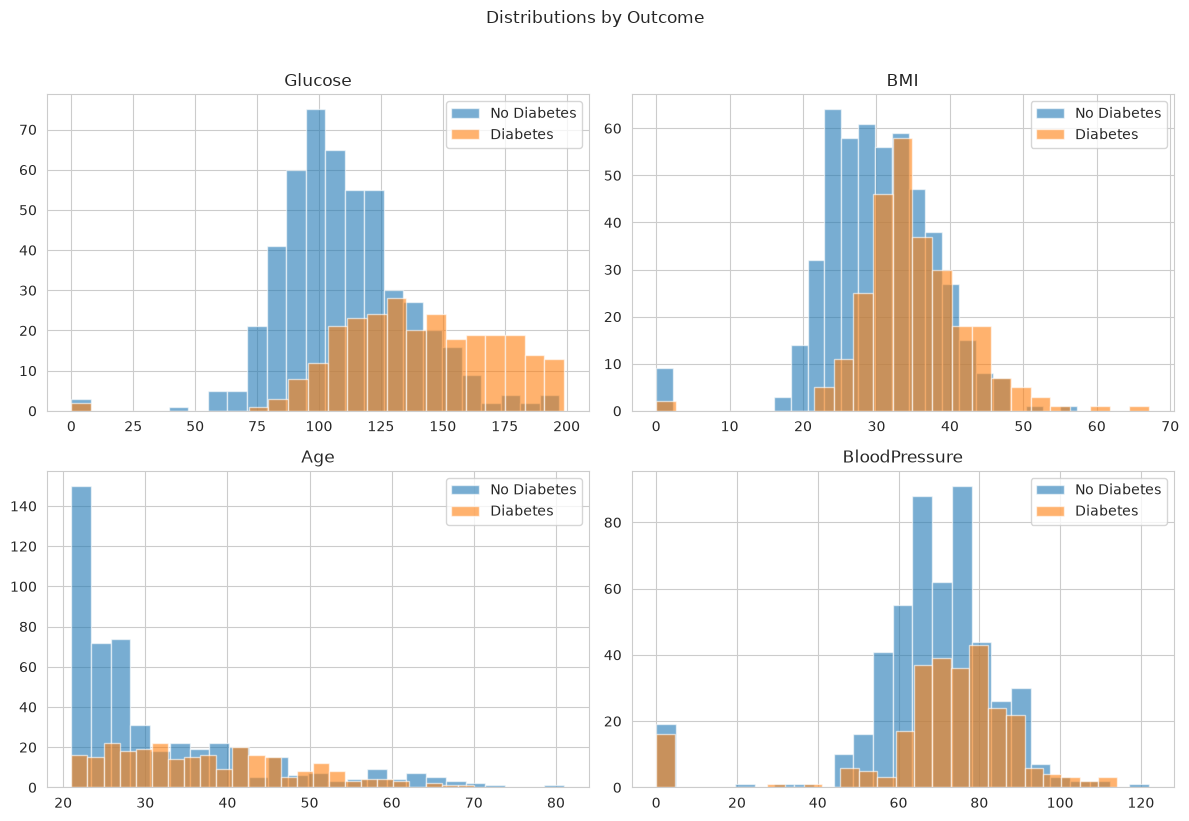

In [5]:
# Histograms split by Outcome for key variables
fig, axes = plt.subplots(2, 2, figsize=(12,8))
for ax, col in zip(axes.flat, ["Glucose","BMI","Age","BloodPressure"]):
    for out, lab in [(0,"No Diabetes"),(1,"Diabetes")]:
        ax.hist(df[df.Outcome==out][col], bins=25, alpha=0.6, label=lab)
    ax.set_title(col); ax.legend()
plt.suptitle("Distributions by Outcome", y=1.02); plt.tight_layout()
plt.savefig("images/fig1_dist_by_outcome.png", dpi=130, bbox_inches="tight"); plt.show()

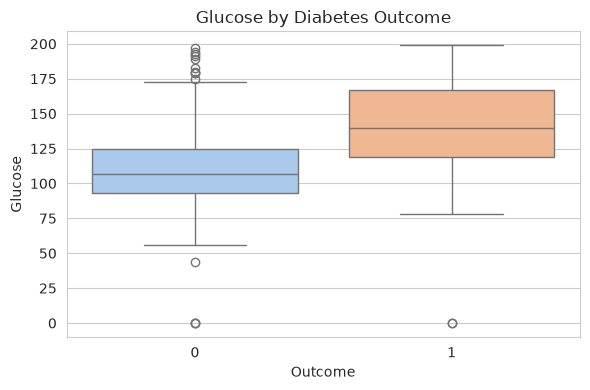

In [6]:
# Boxplot of Glucose by Outcome
plt.figure(figsize=(6,4))
sns.boxplot(x="Outcome", y="Glucose", data=df, palette="pastel")
plt.title("Glucose by Diabetes Outcome")
plt.tight_layout(); plt.savefig("images/fig2_glucose_box.png", dpi=130, bbox_inches="tight"); plt.show()

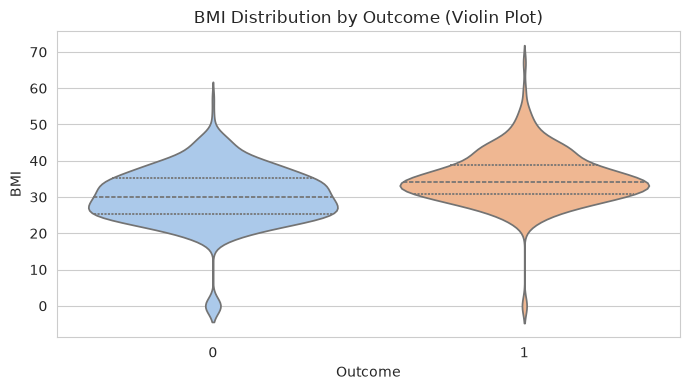

In [7]:
# KDE / violin view of BMI by Outcome
plt.figure(figsize=(7,4))
sns.violinplot(x="Outcome", y="BMI", data=df, palette="pastel", inner="quartile")
plt.title("BMI Distribution by Outcome (Violin Plot)")
plt.tight_layout(); plt.savefig("images/fig3_bmi_violin.png", dpi=130, bbox_inches="tight"); plt.show()

## Key Observations
- Diabetic patients show notably higher mean Glucose, BMI and Age than non-diabetic ones.
- Insulin is highly right-skewed with extreme values.
- Visualizations confirm clear distributional shifts between the two outcome groups.